# Lote prioritario de anotación en CVAT (compensar desequilibrios)

Anotar las imágenes al azar reproduce el desequilibrio de los datos: la gran mayoría de las cajas son coches, y los semáforos rojos y verdes o los peatonales apenas aparecen. Además, la clasificación HSV de las pre-anotaciones etiqueta casi todos los semáforos como **ámbar**, mientras que en la revisión manual del `lote_01` salen sobre todo verdes y rojos.

Este notebook crea un **único job con las imágenes más valiosas para nivelar las clases**, ordenadas de mayor a menor prioridad:

1. **Diagnóstico:** cuántas instancias hay de cada grupo en las pre-anotaciones de los candidatos y en lo ya anotado en CVAT.
2. **Selección voraz** (`src/priorizacion.py`): en cada paso elige la imagen que más aporta a los grupos todavía escasos, teniendo en cuenta lo ya anotado, y reduce el peso de cada grupo a medida que se cubre.
3. **Tarea en CVAT con un solo job**, en orden de prioridad y pre-anotada con YOLO26.
4. **Exportación por jobs terminados**, igual que en `03_anotacion_cvat`; `04_training` lo usa como un lote más.

Grupos considerados: `pedestrian`, `car`, `bus`, `truck`, `motorcycle`, `semaforo` (cualquier color, porque el color pre-anotado no es fiable), `semaforo_rojo` y `semaforo_verde` (indicios HSV), `semaforo_peatonal` y `poca_luz` (noche o crepúsculo). El ámbar no es un grupo a priorizar.

## 1. Configuración

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from config import load_config
from cvat_lotes import (annotation_counts, connect, create_lote, export_lote, get_or_create_project,
                        images_in_lotes, jobs_status, load_task, lote_dir, pre_annotate, task_url)
from pipeline import load_frames, only_service_cameras
from priorizacion import annotated_group_totals, class_balance, greedy_balanced_selection, group_counts

CFG = load_config()
LOTE = CFG["cvat"]["lote_prioritario"]
N_IMAGENES = CFG["cvat"]["n_imagenes_prioritario"]
MAX_POR_CAMARA = CFG["cvat"]["max_por_camara_prioritario"]
MIN_GAP_S = CFG["cvat"]["separacion_minima_min"] * 60   # entre imágenes de la misma cámara

print(f"Lote prioritario: {LOTE} | {N_IMAGENES} imágenes | máx. {MAX_POR_CAMARA} por cámara")

Lote prioritario: lote_02_prioritario | 100 imágenes | máx. 5 por cámara


## 2. Lo ya anotado en CVAT

Cajas por clase de los lotes existentes, separando la pre-anotación (`auto`) de la revisión humana (`manual`, `semi-auto`). Comparar ambas columnas muestra el sesgo de la pre-anotación: por ejemplo, ámbares que el anotador corrige a rojo o verde.

In [2]:
client = connect()
project = get_or_create_project(client)

ya_anotado = []
for task in client.tasks.list():
    if task.project_id != project.id or task.name == LOTE:
        continue
    counts = annotation_counts(client, task)
    print(f"Tarea {task.id} ({task.name}):")
    display(counts)
    ya_anotado.append(counts.sum(axis=1))

initial_totals = annotated_group_totals(pd.concat(ya_anotado, axis=1).sum(axis=1)) if ya_anotado else None

Tarea 1 (lote_01):


origen,manual,semi-auto,auto
clase,,,
pedestrian,13,0,264
car,12,18,1744
bus,10,0,103
truck,5,4,133
motorcycle,7,4,25
traffic_light_red,4,1,5
traffic_light_yellow,0,0,76
traffic_light_green,8,3,3
traffic_light_unknown,8,6,41


## 3. Diagnóstico de desequilibrio en los candidatos

Candidatos: fotogramas válidos con detecciones (fases `frames` + `detections`) que no están en ningún lote. `ratio_vs_mayoritario` indica cuántas veces es más frecuente el grupo mayoritario.

Candidatos: 42386 fotogramas de 121 cámaras


,instancias,imagenes_con_grupo,pct_imagenes,ratio_vs_mayoritario
car,274535.0,38406,90.61,1.0
pedestrian,43275.0,16096,37.97,6.3
truck,20733.0,14001,33.03,13.2
semaforo,20369.0,10442,24.64,13.5
bus,16219.0,10647,25.12,16.9
motorcycle,3940.0,3150,7.43,69.7
poca_luz,3753.0,3753,8.85,73.2
semaforo_peatonal,669.0,631,1.49,410.4
semaforo_rojo,121.0,118,0.28,2268.9
semaforo_verde,36.0,36,0.08,7626.0


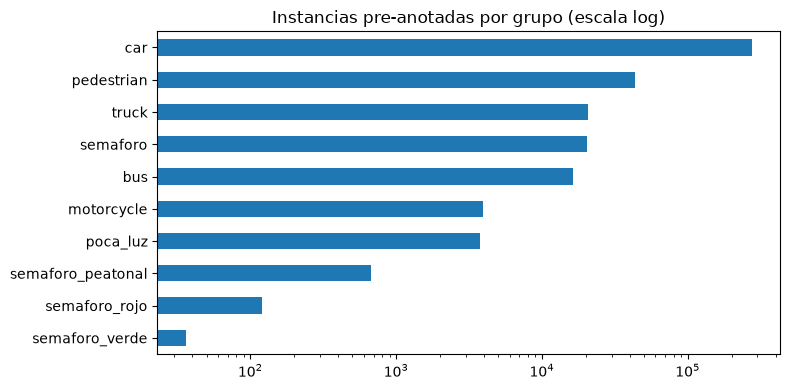

In [3]:
# Solo las 24 cámaras del servicio (las demás tienen 1-2 instantáneas sueltas)
frames = only_service_cameras(load_frames("detections").dropna(subset=["n_car"])).reset_index(drop=True)
frames["image_lote"] = frames["camera"] + "_" + frames["image"]
candidates = frames[~frames["image_lote"].isin(images_in_lotes(exclude=LOTE))].reset_index(drop=True)
counts = group_counts(candidates)

balance = class_balance(counts)
print(f"Candidatos: {len(candidates)} fotogramas de {candidates['camera'].nunique()} cámaras")
display(balance)

ax = balance["instancias"].plot(kind="barh", logx=True, figsize=(8, 4), title="Instancias pre-anotadas por grupo (escala log)")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

## 4. Selección voraz equilibrada

Ganancia de una imagen = Σ_g peso_g · min(n_g, 3), con peso_g = 1 / (1 + total_g), donde total_g incluye lo ya anotado y lo ya seleccionado. El tope de 3 evita que una imagen con muchos coches gane solo por cantidad. Entre dos imágenes de la misma cámara debe haber al menos `separacion_minima_min` (10 min): a 6 s son casi idénticas.

Seleccionadas: 100 imágenes de 25 cámaras


,ya_anotado,aporta_este_lote,total_tras_el_lote
pedestrian,277,194,471
car,1774,749,2523
bus,113,98,211
truck,142,112,254
motorcycle,36,87,123
semaforo,155,117,272
semaforo_rojo,10,20,30
semaforo_verde,14,5,19
semaforo_peatonal,1,57,58
poca_luz,0,61,61


Iluminación: {'dia': 39, 'noche': 34, 'crepusculo': 27}
Franja horaria: {'00:00-02:00': 9, '08:00-10:00': 8, '10:00-12:00': 1, '12:00-14:00': 5, '14:00-16:00': 5, '16:00-18:00': 5, '18:00-20:00': 10, '20:00-22:00': 42, '22:00-00:00': 15}


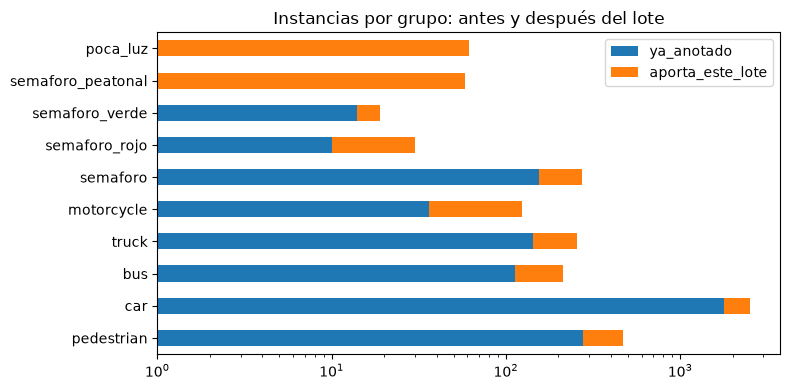

In [4]:
selection, totals_after = greedy_balanced_selection(
    candidates, counts, N_IMAGENES, MAX_POR_CAMARA, initial_totals=initial_totals, min_gap_s=MIN_GAP_S
)
before = initial_totals if initial_totals is not None else pd.Series(0, index=totals_after.index)
comparison = pd.DataFrame({
    "ya_anotado": before.reindex(totals_after.index).fillna(0),
    "aporta_este_lote": totals_after - before.reindex(totals_after.index).fillna(0),
    "total_tras_el_lote": totals_after,
}).astype(int)

print(f"Seleccionadas: {len(selection)} imágenes de {selection['camera'].nunique()} cámaras")
display(comparison)
print("Iluminación:", selection["illumination"].value_counts().to_dict())
print("Franja horaria:", selection["time_slot_2h"].value_counts().sort_index().to_dict())

comparison[["ya_anotado", "aporta_este_lote"]].plot(kind="barh", stacked=True, logx=True, figsize=(8, 4),
                                                   title="Instancias por grupo: antes y después del lote")
plt.tight_layout()
plt.show()

## 5. Crear la tarea en CVAT (un único job ordenado por prioridad) y pre-anotar

Las imágenes se suben en orden de prioridad (`prioridad = 1` es la primera del job), así que, aunque no se termine el job completo, lo anotado primero es lo que más equilibra. Esta celda solo se ejecuta una vez por lote; si el lote ya existe, se reutiliza su tarea.

In [5]:
if (lote_dir(LOTE) / "indice.csv").exists():
    task = load_task(client, LOTE)
    print(f"El lote ya existe: tarea {task.id}")
else:
    selection = selection.assign(image=selection["image_lote"])
    task = create_lote(client, project, LOTE, selection, segment_size=len(selection), keep_order=True)
    print(f"Tarea creada: {task.id} ({task.size} imágenes en un único job)")
    pre_annotate(client, task, CFG["deteccion"]["modelo"], CFG["deteccion"]["conf"], CFG["deteccion"]["imgsz"])
    print("Pre-anotación completada.")

print(f"Abrir en CVAT: {task_url(task)}")
display(jobs_status(task))

Tarea creada: 2 (100 imágenes en un único job)


  0%|          | 0/100 [00:00<?, ?samples/s]

  1%|          | 1/100 [00:25<42:16, 25.62s/samples]

  2%|▏         | 2/100 [00:25<17:26, 10.68s/samples]

  3%|▎         | 3/100 [00:26<09:33,  5.91s/samples]

...

 99%|█████████▉| 99/100 [00:44<00:00,  3.51samples/s]

100%|██████████| 100/100 [00:44<00:00,  3.51samples/s]

100%|██████████| 100/100 [00:44<00:00,  2.23samples/s]

Pre-anotación completada.
Abrir en CVAT: http://localhost:8080/tasks/2


,job,desde,hasta,estado,etapa,asignado
0,7,0,99,new,annotation,None


## 6. Revisión y exportación

Revisar el job en CVAT con el mismo protocolo de `03_anotacion_cvat` (sección 6), prestando especial atención a:
- **Color de los semáforos:** la pre-anotación tiende a marcarlos en ámbar; corregir a rojo, verde o `traffic_light_unknown`.
- **Semáforos peatonales:** cambiar a `pedestrian_light_red` / `pedestrian_light_green`.
- **Noche:** muchas imágenes de este lote son nocturnas; anotar solo lo que se distingue con seguridad.

Al terminar: *Menu → Finish the job* y ejecutar la celda siguiente. Exporta solo los jobs terminados.

In [6]:
indice = export_lote(client, task, LOTE)
print(indice["estado"].value_counts().to_dict())
display(annotation_counts(client, task))

RuntimeError: Ningún job del lote está terminado (Menu -> Finish the job en CVAT).